# Forecasting house prices with STAR

This notebook demonstrates the forecasting workflow, run twice: once on **median** sale prices and
once on **composition-adjusted** prices. For one postcode district and its neighbours it builds the
dataset, fits STAR and three simpler benchmarks, and compares a one-year-ahead forecast with a
three-year-ahead one on years that were held out. It then runs six more districts, times each step,
and shows how to forecast past the last year of data.

The two price measures differ in what moves them. A district's **median** moves when prices change,
and also when the mix of homes that happened to sell changes: more sales on the dearer streets, or
fewer flats. The **adjusted** price holds that mix fixed, so it moves only when prices do.
`from_postcode(..., prices="adjusted")` builds it. The [README](../README.md#composition-adjusted-prices)
sets out the method.

Two companion notebooks do the other jobs.

* [Scenarios](02_scenarios.ipynb) shocks a fitted model ("what if the district next door boomed?") and
  reads off the response the fitted model implies.
* [The random-sample evaluation](03_random_sample_evaluation.ipynb) scores STAR against an AR(1), a
  drift and a no-change forecast on 27 districts and nine forecast origins in two periods, on median
  and on adjusted prices, and tests whether distance in the weights matters at district and at sector
  scale.

The district worked through below, SO45, comes from that sample. It was chosen because its errors are
small enough to read on a chart, and STAR does well on it, so it shows how the tools work rather than
how well the model forecasts. The six districts later on are picked by a fixed rule instead. For the average picture, see notebook 03. On medians STAR(1) beats AR(1) and drift, and against
the no-change forecast the result depends on the period. On adjusted prices STAR(1) ranks better
against the benchmarks over 2007–2019 and worse over 2019–2025.

## 1. The model

Let $P_{i,t}$ be the price of postcode $i$ in year $t$, either the median or the adjusted price (next
section), and $y_{i,t}=\log P_{i,t}$ its log (minus a constant, see *Transform*). The model is about
**growth**. Write $\bar g_i$ for postcode $i$'s average growth per year over the training years, and

$$
z_{i,t} \;=\; y_{i,t} - y_{i,t-1} - \bar g_i
$$

for how much faster or slower than its own average it grew in year $t$. Let $z_t \in \mathbb{R}^N$ stack
the $N$ neighbouring postcodes and let $W$ be a row-standardised $N \times N$ matrix whose entry
$w_{ij}$ is the weight postcode $i$ puts on postcode $j$. Here that is inverse distance between
centroids, so nearer postcodes count for more. Notebook 03 finds that, between districts, equal
weights forecast just as well, and that between postcode sectors nearer ones carry more information.
A **STAR($p$)** model says

$$
(I - \rho W)\, z_t \;=\; \sum_{\ell=1}^{p} \big(\phi_\ell\, z_{t-\ell} + \theta_\ell\, W z_{t-\ell}\big) \;+\; \varepsilon_t,
\qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2 I),
\qquad y_t = y_{t-1} + \bar g + z_t .
$$

Read it one postcode at a time. Postcode $i$'s growth this year, relative to its own average,
depends on

* its **own recent growth**, through $\phi_\ell$ (temporal persistence),
* its **neighbours' recent growth**, through $\theta_\ell\,(Wz_{t-\ell})_i$ (spatial lag in time), and
* its **neighbours' growth this year**, through $\rho\,(Wz_t)_i$ (same-year association: neighbouring
  postcodes tend to move together in the same year. It is a statistical relationship, not an
  established causal spillover, and notebook 03 finds that fixing it at zero forecasts just as well).

Because $z_t$ appears on both sides, predictions solve a linear system,
$z_t = (I-\rho W)^{-1}(\text{right-hand side})$. The parameters are estimated by maximum likelihood:
for a fixed $\rho$ the other coefficients are ordinary least squares, so we maximise the
*concentrated* likelihood over $\rho$ alone.

**Why growth and not price levels?** A level model pulls prices back towards each postcode's training
average. Fitted on a flat decade it forecasts a return to the old average whatever happened last
year; fitted on a trending one it needs near-unit persistence to reproduce the trend and can become
explosive. Describing growth removes both problems and means **every forecast starts from the latest
observed price** and continues at the postcode's usual rate plus whatever its dynamics add.

**Benchmarks.** If the spatial terms do not help, a model that ignores neighbours should do just as
well; and if the average growth $\bar g_i$ does not help, a forecast without it should do just as
well. We use three. The AR(1) and drift share STAR's $\bar g_i$, so they differ from it only in their
dynamics:

* **AR(1)**, fitted separately for every postcode on its own growth: $z_{i,t} = \phi_i\, z_{i,t-1} + \varepsilon_{i,t}$.
  Like STAR in this notebook, it uses one lag, with its coefficient estimated on the training
  years. Neither model's lag is tuned, so they are compared on equal terms; tuning one and not
  the other would favour the tuned model.
* **Drift** (average growth from the latest price): $\hat y_{i,t} = y_{i,t-1} + \bar g_i$. This is STAR and
  AR with every dynamic coefficient set to zero: "prices keep growing at their usual rate from where
  they are now". It is the straight-line forecast anchored at the latest observation.
* **No change** (the latest price carried forward): $\hat y_{i,t} = y_{i,t-1}$, `NoChangeModel`. This
  is drift with the average growth set to zero, and the usual naive benchmark for prices. It is
  hard to beat when growth slows, because it assumes none.

**Transform.** $y_{i,t} = \log P_{i,t} - \bar\ell_i$, where $\bar\ell_i$ is the mean log price of node $i$
**over the training window only**; this just removes the price level so numbers are comparable across
postcodes. $\bar g_i$ is likewise measured on the training window only (the mean yearly change in log
price). Cleaning, the mean, the average growth and the adjusted index's postcode and type effects
all use the training years only, so the hold-out cannot decide which nodes exist or what their
training prices are.

The lag below is fixed at $p = 1$. On annual data [notebook 03](03_random_sample_evaluation.ipynb)
finds that choosing a longer lag from a few walk-forward folds makes the forecasts worse, so the
forecasts in this notebook use one lag throughout.

*A note on plots.* `housing_star` returns **tables** (polars DataFrames, or pandas with
`as_pandas=True`). The neighbourhood map is the exception: `ds.plot_neighbourhood(ax)` draws it
(matplotlib comes from `pip install housing-star[plot]`). The other charts below are ordinary
matplotlib, drawn from the tables.

## 2. One district and its neighbours, two ways

`PriceSeriesDataset.from_postcode` builds everything the model needs. It takes the districts whose
centroids lie within 15 km of the focal district (15 at most, nearest first), records each one's
price per year, and drops or merges a district that is too thin **in the training years**. A merged
district is labelled with both names, such as `SO97+SO18`. The only difference between the two
datasets below is `prices`:

* `prices="median"` (the default) takes the median sale price of each district and year.
* `prices="adjusted"` fits, within each district, log price = year effect + unit-postcode effect +
  property-type effect, and keeps the year effect. A unit postcode such as `SO45 1AB` covers about
  fifteen addresses, so the year effect is the price level of a fixed mix of streets and kinds of
  home. The postcode and type effects are estimated on the **training** years only, and the
  hold-out years are levelled with them held fixed. The level is the price of the district's
  average training sale, in pounds.

The hold-out is the last three years, 2013–2015. Nothing in either fit sees them.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import housing_star as hs
from housing_star.data.series import panel_series
from housing_star.spatial.graph import select_neighbourhood

pl.Config.set_tbl_rows(30).set_tbl_cols(14).set_fmt_float("mixed").set_tbl_width_chars(170)
pl.Config.set_fmt_str_lengths(45)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent

CACHE = hs.TransactionCache(root=ROOT / "ppd_cache" / "random_sample", verbose=False)
GRAPH = hs.GraphConfig(radius_m=15_000, max_nodes=15)
START, END, HOLDOUT = "2001-01-01", "2016-01-01", 3
FOCAL = "SO45"
MEASURES = ("median", "adjusted")


def build(postcode, prices, holdout=HOLDOUT):
    return hs.PriceSeriesDataset.from_postcode(
        postcode,
        start=START,
        end=END,  # exclusive, so the last year is 2015
        freq="1y",
        holdout=holdout,  # 2013-2015 are never used for fitting, cleaning or the adjustment
        graph=GRAPH,
        cache=CACHE,
        prices=prices,
    )


def make_models():
    return {
        "STAR(1)": hs.StarModel(p=1),
        "AR(1)": hs.ArModel(p=1),
        "Drift": hs.DriftModel(),
        "No change": hs.NoChangeModel(),
    }


def plot_holdout(ds, models, protocol, ax, ylabel="Price (£000)"):
    """Actual prices and the forecasts of each model.

    one_step draws each hold-out year as its own segment, starting from that year's actual price.
    recursive draws one path from the last training year, feeding forecasts back in as lags.
    """
    preds = hs.target_predictions(ds, models, protocol=protocol)
    years = [t[:4] for t in ds.times]
    x = np.arange(ds.T)
    train_end = ds.train_end
    price = ds.prices[ds.target_idx] / 1e3
    hold = x[train_end:]
    ax.plot(x[:train_end], price[:train_end], "k-", label="actual (train)")
    ax.plot(x[train_end - 1 :], price[train_end - 1 :], "k--", label="actual (hold-out)")
    for (name,), group in preds.group_by("model", maintain_order=True):
        yhat = group.sort("time")["predicted"].to_numpy() / 1e3
        if protocol == "one_step":
            (line,) = ax.plot(hold, yhat, "o", label=name)
            for t, value in zip(hold, yhat, strict=True):
                ax.plot([t - 1, t], [price[t - 1], value], "-", color=line.get_color(), lw=1)
        else:
            ax.plot(np.r_[train_end - 1, hold], np.r_[price[train_end - 1], yhat], "-", label=name)
            ax.plot(hold, yhat, "o", color=ax.lines[-1].get_color())
    ax.axvline(train_end - 1, color="grey", ls=":")
    ax.set_xticks(x, years)
    ax.set(xlabel="Year", ylabel=ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)


datasets = {measure: build(FOCAL, measure) for measure in MEASURES}
for measure, ds in datasets.items():
    print(
        f"{measure:>8}: {ds.N} nodes x {ds.T} years;  "
        f"training = {ds.times[0][:4]}-{ds.times[ds.train_end - 1][:4]},  "
        f"hold-out = {ds.times[ds.train_end][:4]}-{ds.times[-1][:4]}"
    )
print("nodes (nearest first):", datasets["median"].postcodes)
assert datasets["median"].postcodes == datasets["adjusted"].postcodes

  median: 14 nodes x 15 years;  training = 2001-2012,  hold-out = 2013-2015
adjusted: 14 nodes x 15 years;  training = 2001-2012,  hold-out = 2013-2015
nodes (nearest first): ['SO45', 'SO14', 'SO19', 'SO31', 'SO15', 'SO17', 'SO30', 'SO16', 'SO42', 'SO40', 'PO31', 'PO15', 'PO14', 'SO97+SO18']


Both datasets keep the same fourteen nodes. Here is SO45's price under each measure, and its growth
from one year to the next.

shape: (15, 6)
┌──────┬────────────┬──────────┬──────────┬───────────────────┬─────────────────────┐
│ year ┆ is_holdout ┆ median   ┆ adjusted ┆ median_growth_pct ┆ adjusted_growth_pct │
│ ---  ┆ ---        ┆ ---      ┆ ---      ┆ ---               ┆ ---                 │
│ str  ┆ bool       ┆ f64      ┆ f64      ┆ f64               ┆ f64                 │
╞══════╪════════════╪══════════╪══════════╪═══════════════════╪═════════════════════╡
│ 2001 ┆ false      ┆ 115000.0 ┆ 117161.0 ┆ null              ┆ null                │
│ 2002 ┆ false      ┆ 133000.0 ┆ 136817.0 ┆ 14.5              ┆ 15.5                │
│ 2003 ┆ false      ┆ 156475.0 ┆ 164822.0 ┆ 16.3              ┆ 18.6                │
│ 2004 ┆ false      ┆ 176000.0 ┆ 180965.0 ┆ 11.8              ┆ 9.3                 │
│ 2005 ┆ false      ┆ 171500.0 ┆ 188699.0 ┆ -2.6              ┆ 4.2                 │
│ 2006 ┆ false      ┆ 190000.0 ┆ 193555.0 ┆ 10.2              ┆ 2.5                 │
│ 2007 ┆ false      ┆ 203250.0 ┆ 208251

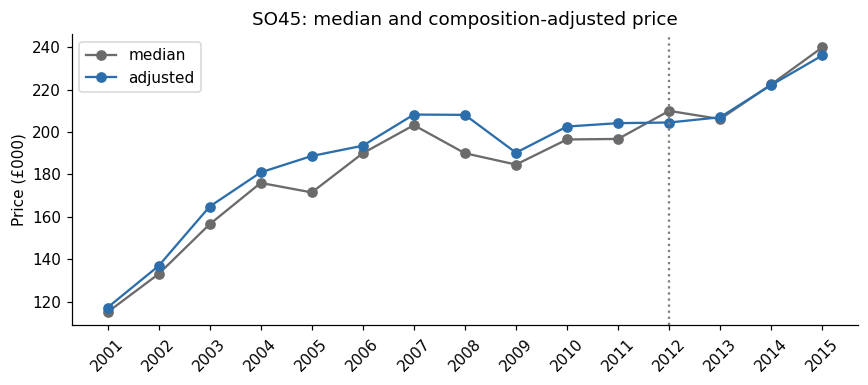

In [2]:
focal_prices = pl.concat(
    [
        ds.to_frame()
        .filter(pl.col("postcode") == FOCAL)
        .select(pl.col("time").dt.year().cast(pl.Utf8).alias("year"), "price", "is_holdout")
        .with_columns(measure=pl.lit(measure))
        for measure, ds in datasets.items()
    ]
).pivot(on="measure", index=["year", "is_holdout"], values="price")
focal_prices = focal_prices.with_columns(
    pl.col("median", "adjusted").round(0),
    median_growth_pct=(100 * pl.col("median").log().diff()).round(1),
    adjusted_growth_pct=(100 * pl.col("adjusted").log().diff()).round(1),
)
print(focal_prices)

fig, ax = plt.subplots(figsize=(8, 3.6))
for measure, color in zip(MEASURES, ("#6b6b6b", "#2c6eac"), strict=True):
    ax.plot(focal_prices["year"], focal_prices[measure] / 1e3, "o-", color=color, label=measure)
ax.axvline(datasets["median"].train_end - 1, color="grey", ls=":")
ax.set(ylabel="Price (£000)", title=f"{FOCAL}: median and composition-adjusted price")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

The two series share a trend, 115,000 to 240,000 for the median and 117,000 to 236,000 adjusted, but
not every year's movement. In 2005 the median fell 2.6% while the adjusted price rose 4.2%; in 2006
the median rose 10.2% against 2.5%. Over 2011–2013 the median went up 6.5% and then down 1.9%, while
the adjusted price was flat until it rose 7.1% in 2014. Those differences are in the mix of homes
that sold. They are the kind of movement a growth model would otherwise try to explain and
forecast. The crash also lands differently: the median fell 6.7% in 2008 and 2.9% in 2009, the
adjusted price 0.1% and 9.0%.

The map shows the nodes. SO45 is in red. Each line is a spatial weight $w_{ij}$; a darker line is a
closer pair, and the weights in a row sum to one. The map and $W$ are the same for both measures.

The cell below is self-contained apart from `cache=`: it builds the dataset again and draws it with
`plot_neighbourhood`, so it can be copied to draw any district's or sector's neighbourhood.

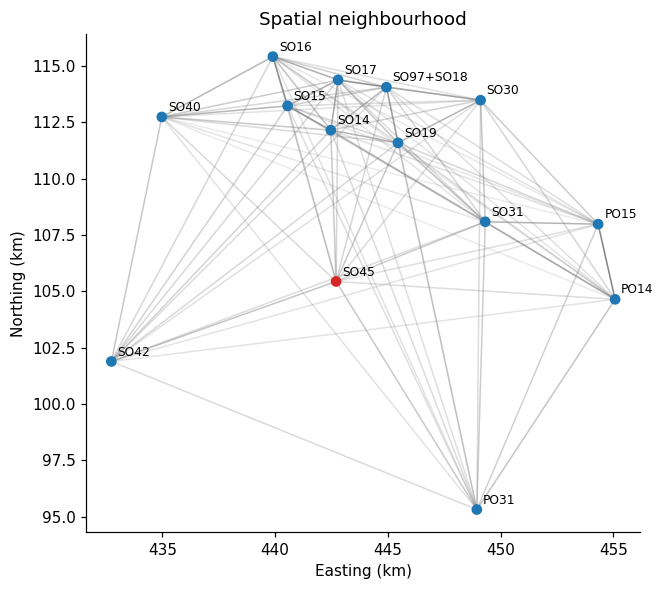

In [3]:
# Self-contained: copy this cell to draw the neighbourhood of any district or sector.
import matplotlib.pyplot as plt

import housing_star as hs

neighbourhood = hs.PriceSeriesDataset.from_postcode(
    "SO45",
    start="2001-01-01",
    end="2016-01-01",
    freq="1y",
    holdout=3,
    graph=hs.GraphConfig(radius_m=15_000, max_nodes=15),
    cache=CACHE,  # this notebook's cache; leave it out to use the default one
)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
neighbourhood.plot_neighbourhood(ax)
plt.show()

## 3. Fit, and score the hold-out

All four models share one interface. `fit` estimates parameters from the training window,
`predict` gives one-step-ahead forecasts from the observed previous year, and `forecast` rolls the
model's own forecasts forward. `evaluate` fits a fresh copy of each model and scores the hold-out.

One step ahead, each hold-out year is predicted from the prices actually observed up to the year
before. The recursive forecast sees only the training window and feeds its own predictions back in.
The first year of the recursive forecast is the one-step forecast, so those two agree; from the
second year they come apart.

The table below is the fitted STAR(1) for each measure, with the focal district's AR(1) coefficient
and average growth.

In [4]:
coefficients = []
for measure, ds in datasets.items():
    models = make_models()
    star = models["STAR(1)"].fit(ds)
    ar = models["AR(1)"].fit(ds)
    drift = models["Drift"].fit(ds)
    i = ds.target_idx
    coefficients.append(
        {
            "measure": measure,
            "rho": star.fit_.rho,
            "phi": float(star.fit_.phi[0]),
            "theta": float(star.fit_.theta[0]),
            "persistence": star.persistence(ds.W),
            "ar1_phi": float(ar.coef_[i, 0]),
            "avg_growth_pct": 100 * np.expm1(drift.growth_[i]),
        }
    )
pl.DataFrame(coefficients).with_columns(pl.col(pl.Float64).round(3))

measure,rho,phi,theta,persistence,ar1_phi,avg_growth_pct
str,f64,f64,f64,f64,f64,f64
"""median""",0.816,-0.304,0.357,0.326,0.266,5.627
"""adjusted""",0.923,-0.172,0.205,0.42,0.444,5.194


On medians, $\hat\rho = 0.82$ is the same-year association with neighbours, $\hat\phi = -0.30$ is
the pull-back from SO45's own growth last year, and $\hat\theta = 0.36$ is the weight on the
neighbours' growth last year. Persistence, the largest eigenvalue of those dynamics, is 0.33, so a
shock to growth fades rather than building. The AR(1) has a single coefficient, $+0.27$.

On adjusted prices the own-lag pull-back is about half as strong ($\hat\phi = -0.17$) and the AR(1)
coefficient is larger ($+0.44$). A negative own lag is partly the signature of mix noise: a year that
comes out high because dearer homes sold tends to be followed by one that comes out lower. With the
mix removed, less of that reversal is left and more of a year's growth carries into the next.
$\hat\rho$ rises to 0.92: adjusted neighbours move together even more closely in the same year.
Average growth is 5.2% a year adjusted and 5.6% on medians.

In [5]:
scores = pl.concat(
    [
        hs.evaluate(ds, make_models(), protocol=protocol).with_columns(measure=pl.lit(measure))
        for measure, ds in datasets.items()
        for protocol in ("one_step", "recursive")
    ]
)
scores.pivot(on="measure", index=["protocol", "model"], values="mape").with_columns(
    pl.col(pl.Float64).round(2)
)

protocol,model,median,adjusted
str,str,f64,f64
"""one_step""","""STAR(1)""",3.36,1.84
"""one_step""","""AR(1)""",4.48,1.83
"""one_step""","""Drift""",3.94,2.32
"""one_step""","""No change""",5.5,4.65
"""recursive""","""STAR(1)""",2.19,1.66
"""recursive""","""AR(1)""",5.7,1.91
"""recursive""","""Drift""",5.35,2.2
"""recursive""","""No change""",6.66,7.52


The table is the focal district's MAPE (%), the mean absolute percentage error on the price in
pounds, one column per measure.

* **Medians.** One year ahead STAR's MAPE is 3.4%, against 3.9% for drift, 4.5% for the AR(1) and
  5.5% for no change. Three years ahead it is 2.2% against 5.4% for drift, 5.7% for the AR(1) and
  6.7% for no change.
* **Adjusted prices.** One year ahead STAR and the AR(1) tie at 1.8%, with drift at 2.3% and no
  change at 4.7%. Three years ahead STAR has 1.7%, the AR(1) 1.9%, drift 2.2% and no change 7.5%.

**The two columns forecast different series, so they are not a contest between the measures.** Each
measure is scored against its own hold-out values. The adjusted series has less year-to-year noise to
forecast, so every growth model's error is lower partly because the target is smoother. What the
comparison does show is how the ranking of the models depends on the measure. On adjusted prices the
three growth models are closer together, and the AR(1) catches up with STAR one year ahead: once mix
noise is removed, a district's own last year tells more about the next. The no-change forecast is
worse on adjusted prices three years ahead, because the adjusted price rose more steadily over
2013–2015 and no change assumes no growth at all.

## 4. One year ahead, and three years ahead

The same forecasts, drawn: medians on the top row, adjusted prices below. The dotted vertical line is
the last training year, 2012.

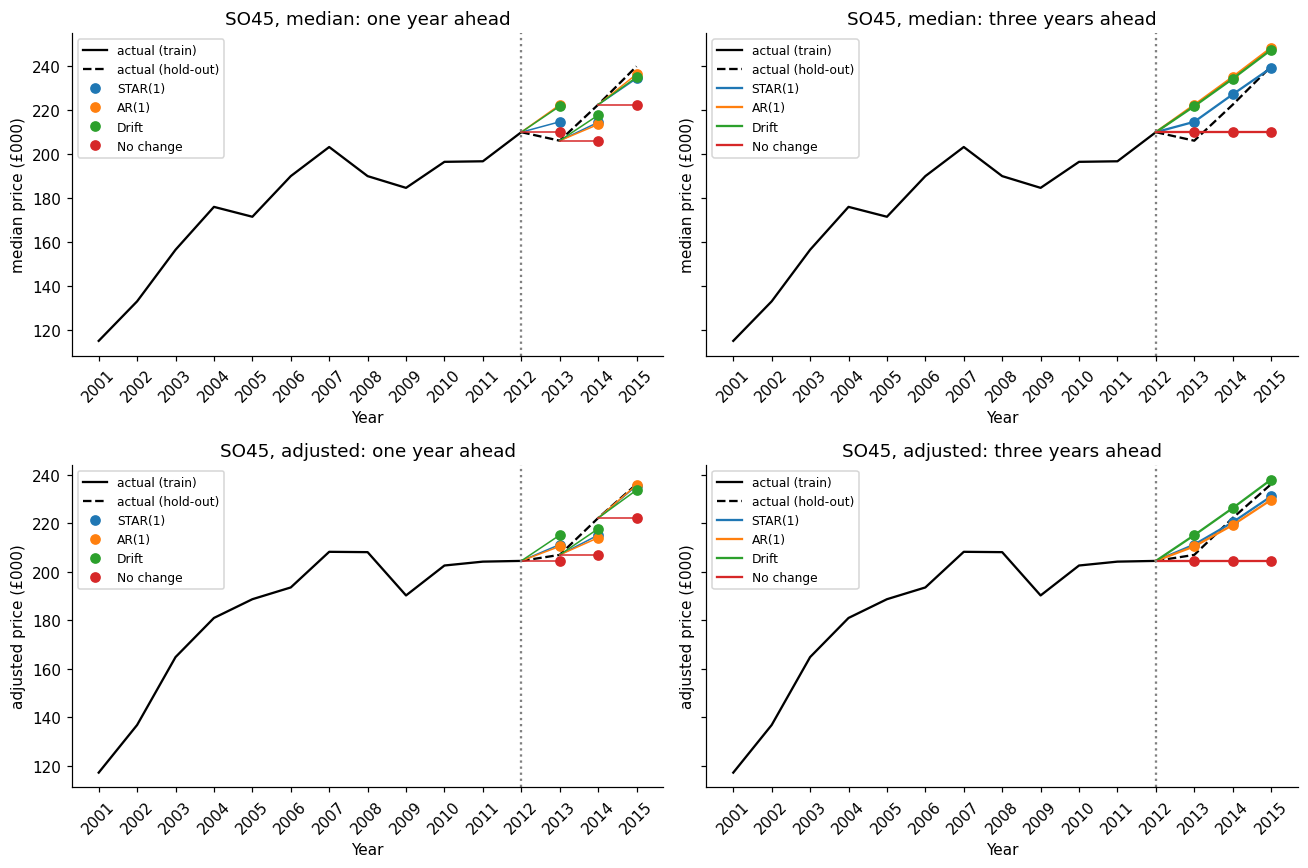

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey="row")
titles = {"one_step": "one year ahead", "recursive": "three years ahead"}
for row, measure in enumerate(MEASURES):
    for col, protocol in enumerate(("one_step", "recursive")):
        ax = axes[row, col]
        plot_holdout(
            datasets[measure], make_models(), protocol, ax, ylabel=f"{measure} price (£000)"
        )
        ax.set_title(f"{FOCAL}, {measure}: {titles[protocol]}")
plt.tight_layout()
plt.show()

In [7]:
def prediction_table(ds, protocol):
    """Actual and predicted prices (£) of the focal district, with the percentage error."""
    names = list(make_models())
    wide = (
        hs.target_predictions(ds, make_models(), protocol=protocol)
        .pivot(on="model", index=["time", "actual"], values="predicted")
        .sort("time")
    )
    return wide.select(
        pl.col("time").str.slice(0, 4).alias("year"),
        pl.col("actual").round(0),
        *[pl.col(name).round(0) for name in names],
        *[
            (100 * (pl.col(name) / pl.col("actual") - 1)).round(1).alias(f"{name} %")
            for name in names
        ],
    )


for measure, ds in datasets.items():
    print(
        f"{measure} prices, one year ahead: each year predicted from the actual price the year before"
    )
    print(prediction_table(ds, "one_step"))
    print(f"{measure} prices, three years ahead: one forecast made at the end of 2012")
    print(prediction_table(ds, "recursive"))
    print()

median prices, one year ahead: each year predicted from the actual price the year before
shape: (3, 10)
┌──────┬──────────┬──────────┬──────────┬──────────┬───────────┬───────────┬─────────┬─────────┬─────────────┐
│ year ┆ actual   ┆ STAR(1)  ┆ AR(1)    ┆ Drift    ┆ No change ┆ STAR(1) % ┆ AR(1) % ┆ Drift % ┆ No change % │
│ ---  ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---       ┆ ---       ┆ ---     ┆ ---     ┆ ---         │
│ str  ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64       ┆ f64       ┆ f64     ┆ f64     ┆ f64         │
╞══════╪══════════╪══════════╪══════════╪══════════╪═══════════╪═══════════╪═════════╪═════════╪═════════════╡
│ 2013 ┆ 206125.0 ┆ 214727.0 ┆ 222433.0 ┆ 221817.0 ┆ 210000.0  ┆ 4.2       ┆ 7.9     ┆ 7.6     ┆ 1.9         │
│ 2014 ┆ 222500.0 ┆ 214477.0 ┆ 213517.0 ┆ 217724.0 ┆ 206125.0  ┆ -3.6      ┆ -4.0    ┆ -2.1    ┆ -7.4        │
│ 2015 ┆ 239950.0 ┆ 234445.0 ┆ 236380.0 ┆ 235020.0 ┆ 222500.0  ┆ -2.3      ┆ -1.5    ┆ -2.1    ┆ -7.3        │
└──────┴

How to read the charts and the tables:

* **One step ahead (left).** Each coloured segment starts on the actual price and ends at that
  year's forecast, so the three dots are three separate one-year forecasts rather than a path. On
  medians, the 2013 median fell from £210,000 to £206,000. The no-change forecast stayed at £210,000
  and was the closest; STAR came out at £215,000, and drift and the AR(1) at £222,000. On adjusted
  prices 2013 was a small rise, from £204,500 to £207,000, and every growth model's forecast is
  within 4% of it. In 2014 and 2015 both series rose by 6–8% a year; the growth models sit a little
  below, and the no-change forecast is about 6–7% too low each year.
* **Three years ahead (right).** One forecast made at the end of 2012 and run forward on the model's
  own predictions. On medians, drift finishes at £247,000 against an actual £240,000, and STAR at
  £239,000. On adjusted prices the growth models finish between £230,000 and £238,000 against
  £236,000. The no-change forecast stays at its 2012 level and is 12.5% too low by 2015 on medians,
  13.4% on adjusted prices.

The median forecasts start from a 2012 value that the mix had pushed up (£210,000, after a rise of
6.5%), and the median fell back in 2013. The adjusted series has no such step, so its one-year-ahead
errors in 2013 are smaller for every growth model.

## 5. Several districts at once

The same window, the same neighbourhood rule and the same four models, for six more districts, each
built with both measures. They are the first six districts in notebook 03's sample, in its
alphabetical order, that keep at least four nodes on this window. That rule was fixed before any
score was looked at, so these six are not chosen to flatter any model. The table is the focal
district's MAPE (%) for each model, measure and protocol. The second table is each district's
average training growth and its first and last training price under each measure. The figure is the
three-year recursive forecast on adjusted prices.

In [8]:
# The first six districts in notebook 03's sample, in its alphabetical order, that keep at least
# four nodes on this window (CA12 does not). The rule was fixed before any score was looked at.
PANEL = ["B17", "BH15", "CF33", "DL17", "FY8", "GL5"]

rows, fitted = [], {}
for postcode in PANEL:
    for measure in MEASURES:
        district = build(postcode, measure)
        fitted[(postcode, measure)] = district
        for protocol in ("one_step", "recursive"):
            rows.append(
                hs.evaluate(district, make_models(), protocol=protocol).with_columns(
                    postcode=pl.lit(postcode), measure=pl.lit(measure), n_nodes=pl.lit(district.N)
                )
            )
results = pl.concat(rows)

# Which model has the lowest MAPE for each district, protocol and price measure.
best = (
    results.sort("mape")
    .group_by("postcode", "protocol", "measure")
    .first()
    .group_by("measure", "protocol", "model")
    .len()
    .sort("measure", "protocol", "len", descending=[False, False, True])
)
print("Lowest focal-district MAPE, number of districts out of 6:")
for (measure, protocol), group in best.group_by("measure", "protocol", maintain_order=True):
    wins = ", ".join(f"{m} {n}" for m, n in group.select("model", "len").rows())
    print(f"  {measure:>8}, {protocol:>9}: {wins}")

# MAPE (%) of the focal district: one row per district and protocol, one column per model and price.
results.with_columns(column=pl.col("model") + " · " + pl.col("measure")).pivot(
    on="column", index=["postcode", "n_nodes", "protocol"], values="mape"
).sort("postcode", "protocol").with_columns(pl.col(pl.Float64).round(1))

Lowest focal-district MAPE, number of districts out of 6:
  adjusted,  one_step: STAR(1) 5, Drift 1
  adjusted, recursive: STAR(1) 6
    median,  one_step: STAR(1) 3, Drift 2, AR(1) 1
    median, recursive: STAR(1) 3, AR(1) 2, Drift 1


postcode,n_nodes,protocol,STAR(1) · median,AR(1) · median,Drift · median,No change · median,STAR(1) · adjusted,AR(1) · adjusted,Drift · adjusted,No change · adjusted
str,i32,str,f64,f64,f64,f64,f64,f64,f64,f64
"""B17""",15,"""one_step""",4.5,5.9,5.7,5.4,2.8,3.6,2.8,4.7
"""B17""",15,"""recursive""",3.5,5.0,5.1,6.3,2.6,4.1,4.2,6.5
"""BH15""",15,"""one_step""",3.8,4.6,4.3,5.8,1.6,2.4,2.3,4.5
"""BH15""",15,"""recursive""",3.5,3.6,5.8,6.3,1.3,1.6,3.2,7.2
"""CF33""",8,"""one_step""",2.5,6.2,5.5,4.7,2.7,3.8,3.4,4.5
"""CF33""",8,"""recursive""",3.8,6.2,8.7,6.1,2.6,6.8,9.6,5.1
"""DL17""",12,"""one_step""",12.1,4.7,10.5,7.7,3.4,4.0,5.4,5.4
"""DL17""",12,"""recursive""",20.2,6.9,21.3,7.9,2.6,10.6,13.6,4.2
"""FY8""",10,"""one_step""",2.6,3.1,2.5,3.9,1.7,1.7,3.0,3.0


In [9]:
growth = []
for postcode in PANEL:
    row = {"postcode": postcode}
    for measure in MEASURES:
        district = fitted[(postcode, measure)]
        i = district.target_idx
        train_growth = 100 * np.expm1(district.growth_means[i])
        prices = district.prices[i]
        row[f"{measure} training growth %"] = round(float(train_growth), 1)
        row[f"{measure} {district.times[0][:4]}"] = round(float(prices[0]))
        row[f"{measure} {district.times[district.train_end - 1][:4]}"] = round(
            float(prices[district.train_end - 1])
        )
    growth.append(row)
pl.DataFrame(growth)

postcode,median training growth %,median 2001,median 2012,adjusted training growth %,adjusted 2001,adjusted 2012
str,f64,i64,i64,f64,i64,i64
"""B17""",6.0,109000,206000,5.6,111171,203426
"""BH15""",5.6,109950,200000,5.5,108442,195883
"""CF33""",6.7,49000,100000,6.8,48600,99708
"""DL17""",7.8,24975,57000,6.7,22910,46587
"""FY8""",6.7,78600,160000,6.2,81928,159277
"""GL5""",5.7,92000,170000,5.5,101187,182281


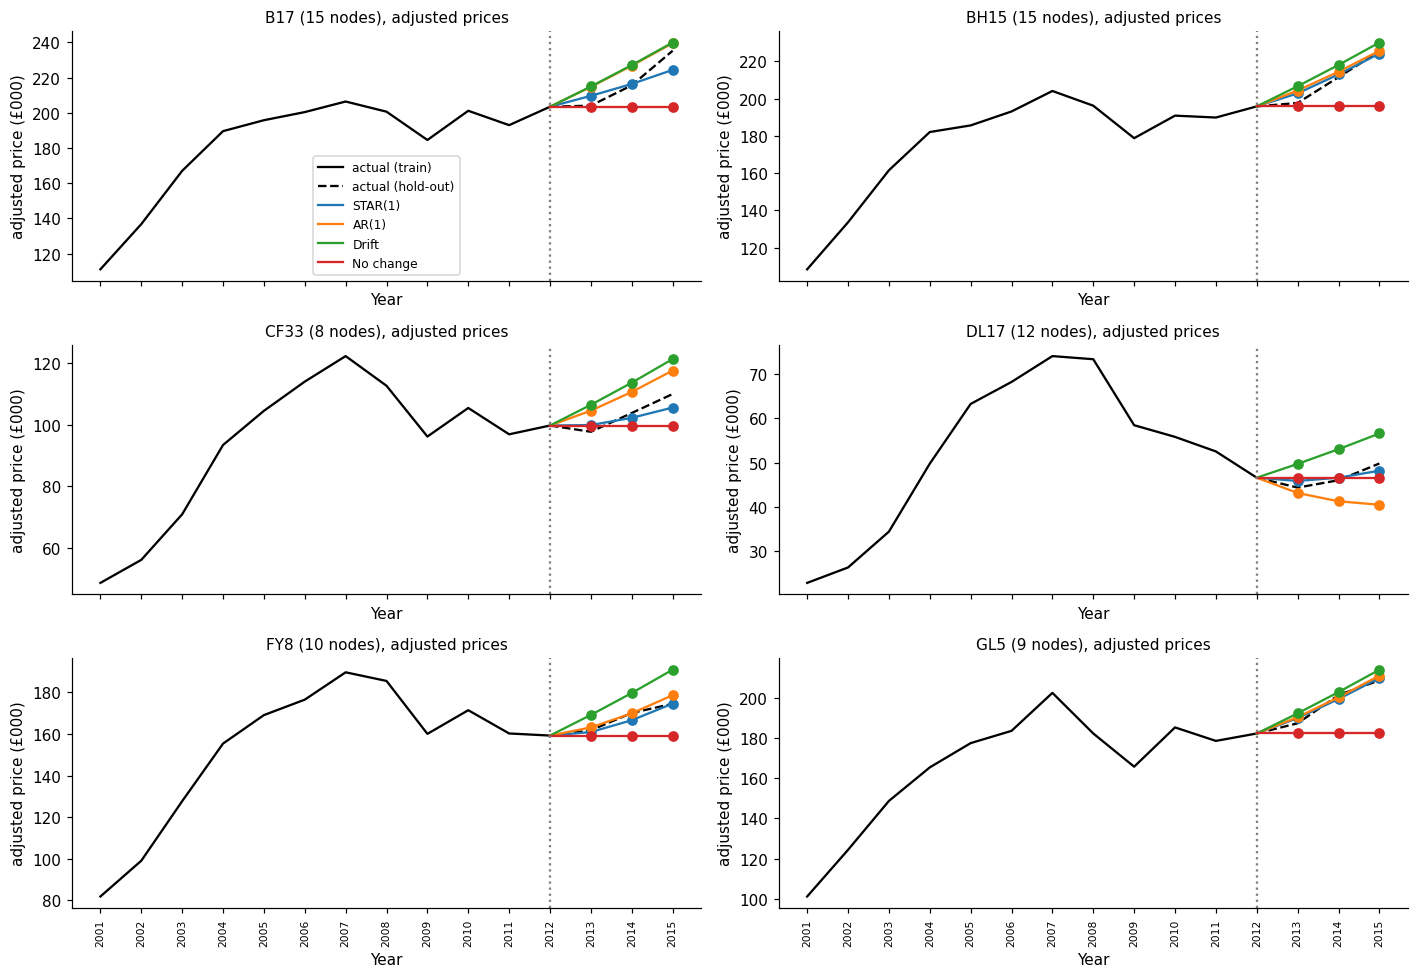

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for ax, postcode in zip(axes.flat, PANEL, strict=True):
    district = fitted[(postcode, "adjusted")]
    plot_holdout(district, make_models(), "recursive", ax, ylabel="adjusted price (£000)")
    ax.set_title(f"{postcode} ({district.N} nodes), adjusted prices", fontsize=10)
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    if ax is not axes.flat[0]:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()

On **medians** the picture is mixed: STAR(1) has the lowest error in three of the six districts
under both protocols. On **adjusted prices** it has the lowest three-year error in all six, and the
lowest one-year error in five, with drift lower in GL5. The same caution applies as for SO45: each
column is scored against its own series, so these are not like-for-like errors across measures, and
six districts on one window can land either way. Across notebook 03's whole sample, adjusted prices rank STAR(1) better against the benchmarks over
2007–2019 and worse over 2019–2025, when a strong run of growth ended in 2023.

* **DL17** changes most. Its median rose from £25,000 in 2001 to £57,000 in 2012, an average of 7.8% a
  year. The adjusted price rose from £23,000 to £47,000, 6.7% a year: part of the median's rise was a
  shift towards dearer homes. Then prices fell. On medians STAR and drift carry the higher average
  forward and their three-year errors are 20.2% and 21.3%. On adjusted prices STAR's is 2.6%, against
  10.6% for the AR(1), 13.6% for drift and 4.2% for no change.
* **GL5** grew steadily at close to its average rate, so drift is almost exact on medians (0.3% one
  year ahead, 0.2% three years ahead). On adjusted prices STAR is closest three years ahead (1.0%).
* **BH15** goes from a close call three years ahead on medians (STAR 3.5% against 3.6% for the
  AR(1)) to a clearer lead on adjusted prices (1.3% against 1.6%). In **FY8** STAR is behind the
  AR(1) three years ahead on medians (4.3% against 3.2%) and just ahead on adjusted prices (0.9%
  against 1.1%).

2013–2015 was a period of rising prices, and the no-change forecast is the worst of the four three
years ahead in four of the six districts on medians and in three on adjusted prices. Notebook 03 shows the opposite in the years after
2008, when it beats every growth model on medians.

## 6. How long each step takes

The table times every step for SO45, both measures, with the sales already in the cache. Each figure
is the median of seven runs, in milliseconds.

1. **Read sales from the cache**: the Parquet files of the 15 districts in the neighbourhood (SO97 and
   SO18 are still separate here; cleaning merges them later). The same for both measures.
2. **Turn sales into prices**: `panel_series` minus step 1. For medians, a group-by. For adjusted
   prices, the least-squares fit for every district.
3. **Clean the panel and build $W$**: `from_panel`.
4. **Fit** each model on the dataset.
5. **Evaluate**: `hs.evaluate` for one protocol, which refits all four models and scores them.

The last row is `from_postcode` end to end, which is steps 1–3 in one call. A first run that has to
download from Land Registry is far slower than any of these and is not timed: downloading is the
same for both measures, and the cache makes it a one-off.

In [11]:
REPEATS = 7


def timed(step, repeats=REPEATS):
    """Median wall time of ``step()`` over ``repeats`` runs, in milliseconds."""
    times = []
    for _ in range(repeats):
        started = time.perf_counter()
        step()
        times.append(time.perf_counter() - started)
    return 1_000 * float(np.median(times))


hood = select_neighbourhood(FOCAL, radius_m=GRAPH.radius_m, max_nodes=GRAPH.max_nodes)
read_ms = timed(lambda: [CACHE.transactions(node, START, END) for node in hood.keys])
runtime = {}
for measure in MEASURES:
    ds = datasets[measure]
    panel_ms = timed(
        lambda measure=measure: panel_series(
            hood.keys, start=START, end=END, freq="1y", cache=CACHE, prices=measure, holdout=HOLDOUT
        )
    )
    panel = panel_series(
        hood.keys, start=START, end=END, freq="1y", cache=CACHE, prices=measure, holdout=HOLDOUT
    )
    steps = {
        "1. read sales from the cache": read_ms,
        "2. turn sales into prices": panel_ms - read_ms,
        "3. clean the panel, build W": timed(
            lambda panel=panel: hs.PriceSeriesDataset.from_panel(
                panel, hood, target=FOCAL, holdout=HOLDOUT, eps_m=GRAPH.eps_m
            )
        ),
    }
    for name, model in make_models().items():
        steps[f"4. fit {name}"] = timed(lambda model=model, ds=ds: model.fit(ds))
    for protocol in ("one_step", "recursive"):
        steps[f"5. evaluate, {protocol} (refits all four)"] = timed(
            lambda protocol=protocol, ds=ds: hs.evaluate(ds, make_models(), protocol=protocol)
        )
    steps["from_postcode, end to end (1-3)"] = timed(lambda measure=measure: build(FOCAL, measure))
    runtime[measure] = steps

timings = pl.DataFrame(
    {
        "step": list(runtime["median"]),
        "median (ms)": list(runtime["median"].values()),
        "adjusted (ms)": list(runtime["adjusted"].values()),
    }
).with_columns(
    (pl.col("adjusted (ms)") - pl.col("median (ms)")).alias("difference (ms)"),
)
print(
    f"{FOCAL}: {len(hood.keys)} districts, {sum(CACHE.transactions(n, START, END).height for n in hood.keys):,} sales; "
    f"median of {REPEATS} runs, cache already on disk"
)
timings.with_columns(pl.col(pl.Float64).round(1))

SO45: 15 districts, 123,453 sales; median of 7 runs, cache already on disk


step,median (ms),adjusted (ms),difference (ms)
str,f64,f64,f64
"""1. read sales from the cache""",140.1,140.1,0.0
"""2. turn sales into prices""",26.4,139.4,113.0
"""3. clean the panel, build W""",4.0,2.3,-1.7
"""4. fit STAR(1)""",1.0,1.0,0.0
"""4. fit AR(1)""",0.1,0.1,-0.0
"""4. fit Drift""",0.0,0.0,-0.0
"""4. fit No change""",0.0,0.0,0.0
"""5. evaluate, one_step (refits all four)""",1.5,1.5,0.0
"""5. evaluate, recursive (refits all four)""",1.6,1.6,-0.0


In [12]:
panel_runtime = []
for measure in MEASURES:
    build_ms = timed(lambda measure=measure: [build(p, measure) for p in PANEL], repeats=3)
    evaluate_ms = timed(
        lambda measure=measure: [
            hs.evaluate(fitted[(p, measure)], make_models(), protocol=protocol)
            for p in PANEL
            for protocol in ("one_step", "recursive")
        ],
        repeats=3,
    )
    panel_runtime.append(
        {
            "measure": measure,
            "build 6 datasets (ms)": build_ms,
            "evaluate 6 x 2 protocols (ms)": evaluate_ms,
        }
    )
pl.DataFrame(panel_runtime).with_columns(pl.col(pl.Float64).round(0))

measure,build 6 datasets (ms),evaluate 6 x 2 protocols (ms)
str,f64,f64
"""median""",798.0,17.0
"""adjusted""",1265.0,17.0


Reading the cache dominates everything for medians. The adjusted index adds about a tenth of a
second per neighbourhood, so building a dataset takes about a quarter of a second instead of about
a sixth. Fitting and scoring the four models takes a few milliseconds either way: the models see
the same-sized panel of prices whichever measure built it. Over the six districts, building the
datasets takes about 1.3 seconds with adjusted prices against about 0.8 with medians, and evaluating
them takes a few hundredths of a second for both.

The times depend on the machine and on how many sales the neighbourhood has. The adjusted fit grows
with the number of sales and unit postcodes in each district; the model fits depend only on the
number of nodes and years.

## 7. Forecast past the last year you have

The scores above are a historical evaluation. Each hold-out year is compared with a price that has
already been observed. A forecast you would publish has no later year to score it against. It has to
start from the latest price you do have.

On the evaluation datasets those are not the same date.

* **Fitting uses the training split.** `fit` reads `y_train()` only. Here that is 2001–2012. The
  average growth, the log-price mean, cleaning and the adjusted index's effects all use that window.
* **A forecast starts from the last column of the dataset you pass.** `forecast(ds, 3)` on the
  evaluation dataset would start at the 2015 price while the coefficients were estimated through
  2012. The hold-out charts avoid that mix: they forecast from `ds.train_only()`, whose last column
  is 2012, and then score 2013–2015.

To forecast 2016–2018, **rebuild** the dataset with `holdout=0`, so that every observed year informs
cleaning, the means and, for adjusted prices, the postcode and type effects. Then refit and forecast
from the last price. `ds.with_holdout(0)` is a quicker way to move the split on an existing dataset.
It recomputes the means and growth, but it keeps the cleaning and the adjusted effects estimated on
the old training years, so rebuilding is the safer habit. STAR(1) is used below to show the
mechanics; it is not a recommendation over the benchmarks, which notebook 03 compares.

Cleaning can merge the district you asked for into a neighbour. This neighbourhood already has one
merged node, `SO97+SO18`. The row to publish is the node that contains your postcode,
`postcodes[target_idx]`. That is still `SO45` here, and would be the merged label if SO45 had been the
district that was grouped.

In [13]:
# Rebuild on every observed year, so cleaning, the means and the adjusted index's postcode and type
# effects all use 2001-2015, then refit STAR(1) and forecast from the latest price.
rows = []
for measure in MEASURES:
    full = build(FOCAL, measure, holdout=0)
    forward = hs.StarModel(p=1).fit(full)
    forecasts = forward.forecast_frame(full, horizon=3)
    # The effective target is the node that contains the postcode, after any merge.
    target = full.postcodes[full.target_idx]
    last_year = int(full.times[-1][:4])
    rows.append(
        forecasts.filter(pl.col("postcode") == target).select(
            pl.lit(measure).alias("measure"),
            (pl.lit(last_year) + pl.col("step")).alias("year"),
            pl.col("forecast").round(0),
        )
    )
    print(
        f"{measure:>8}: fit on {full.times[0][:4]}-{full.times[-1][:4]}, "
        f"last observed price £{float(full.prices[full.target_idx, -1]):,.0f}"
    )
forward_forecasts = pl.concat(rows).pivot(on="measure", index="year", values="forecast")
saved = ROOT / f"{FOCAL}_forecast.csv"
forward_forecasts.write_csv(saved)
print(forward_forecasts)
print(f"Saved {saved.relative_to(ROOT)}")

  median: fit on 2001-2015, last observed price £239,950


adjusted: fit on 2001-2015, last observed price £238,384
shape: (3, 3)
┌──────┬──────────┬──────────┐
│ year ┆ median   ┆ adjusted │
│ ---  ┆ ---      ┆ ---      │
│ i64  ┆ f64      ┆ f64      │
╞══════╪══════════╪══════════╡
│ 2016 ┆ 253378.0 ┆ 252304.0 │
│ 2017 ┆ 267522.0 ┆ 265943.0 │
│ 2018 ┆ 282028.0 ┆ 279929.0 │
└──────┴──────────┴──────────┘
Saved SO45_forecast.csv


Both forecasts start from the 2015 price and run three years forward. The adjusted 2015 price is
£238,384 here, against £236,150 in the evaluation dataset. Rebuilding with every year re-estimates
the postcode and type effects, so earlier adjusted prices can move slightly, as published price
indexes are revised. The two measures forecast about the same path for SO45, rising to about
£280,000 by 2018.

`forecasts` has one row per district in the neighbourhood and per year ahead (`step` 1 is the first
year after the last observation). The table keeps the effective target only. The file
`SO45_forecast.csv` holds both columns. A shock to a neighbour, rather than a forecast of the path as
it stands, is the subject of [the scenarios notebook](02_scenarios.ipynb).